In [58]:
# Import NumPy and give it the conventional short name np.
import numpy as np

# Import pandas and give it the conventional short name pd.
import pandas as pd

# Import Matplotlib's pyplot interface for plotting.
import matplotlib.pyplot as plt

# Import Seaborn for statistical graphics.
import seaborn as sns

# Import Plotly Express for interactive graphics.
import plotly.express as px

# Import SciPy's statistics module for inferential tests.
from scipy import stats

# Import Path to work with file paths cleanly.
from pathlib import Path

# Make pandas display more columns when we inspect a DataFrame.
pd.set_option("display.max_columns", 50)

# Set a clean Seaborn plotting theme.
sns.set_theme(style="whitegrid")

# Use the first color from the active plotting theme for single-series Seaborn plots.
DEFAULT_COLOR = sns.color_palette()[0]

print("Libraries imported successfully.")

Libraries imported successfully.


In [59]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [60]:
from pathlib import Path
import pandas as pd

# Define the dataset path.
DATA_PATH = Path("/content/Titanic-Dataset.csv")

# Check whether the dataset exists.
if not DATA_PATH.exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        DATA_PATH = Path(next(iter(uploaded.keys())))
    except Exception as e:
        raise FileNotFoundError(
            "Titanic-Dataset.csv was not found. Please upload the file and run this cell again."
        ) from e

# Read the CSV file into a pandas DataFrame.
df_raw = pd.read_csv(DATA_PATH)

# Display the first five observations.
df_raw.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [61]:
# Basics Explore
print("Shape:",df_raw.shape )
print("\nMissing values:")
print(df_raw.isna().sum())
print("\nExact duplicate rows:", df_raw.duplicated().sum())
print("\nData types:")
print(df_raw.dtypes)

Shape: (891, 12)

Missing values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Exact duplicate rows: 0

Data types:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


In [62]:
# 1. NumPy for Scientific Computing
scores = np.array([65,72,80,91,88]) # Create a one-dimensional Numpy array.
# Display the array
print("Array:",scores)
# Display the Numpy objective type
print("Object type:", type(scores))



Array: [65 72 80 91 88]
Object type: <class 'numpy.ndarray'>


In [63]:
#2. Arrays and Dimensions: Create a two dimensional Array(Matrix)
matrix = np.array([
    [1,2,3],
    [4,5,6],
    [7,8,9]
])

# View the matrix
print( matrix)
print("Shape:", matrix.shape)
print("Total elements:", matrix.size)

[[1 2 3]
 [4 5 6]
 [7 8 9]]
Shape: (3, 3)
Total elements: 9


In [64]:
# Indexing and Slicing
x = np.array([10, 20, 30,40,50,60])
# First Value: Python inexing starts at 0.
print("First:", x[0])
print("Last:", x[-1]) # -1 means the final position
print("Slice from index 1 upto four", x[1:4])
print("First three values:", x[:3]) # First three values
print("x[::2]", x[::2])

First: 10
Last: 60
Slice from index 1 upto four [20 30 40]
First three values: [10 20 30]
x[::2] [10 30 50]


In [65]:
# Select the value in row 0, column 1.
print("matrix[0,1]=", matrix[0,1])
#Select a 2* 2 block from the upper left area
print("2*2 :\n", matrix[:2,2])
# Select the second column
print("Second column:", matrix[:,1])

matrix[0,1]= 2
2*2 :
 [3 6]
Second column: [2 5 8]


In [66]:
# Array Operations
a = np.array([1, 2, 3, 4, 5, 6])
# Add 10 to every element.
print("a+10=", a+10)
# Multiply every element by 2
print("a*2=", a*2)
# Squared every element
print(" a squared =", a**2)
# Take the sqaure root of every element.
print("sqrt(a)=",np.sqrt(a))

a+10= [11 12 13 14 15 16]
a*2= [ 2  4  6  8 10 12]
 a squared = [ 1  4  9 16 25 36]
sqrt(a)= [1.         1.41421356 1.73205081 2.         2.23606798 2.44948974]


In [67]:
# Vectorization

In [68]:
# Broadcastings
x = np.array([10, 20, 30])
x + 5
matrix = np.array([
    [1, 2, 3],
    [4, 5, 6]
])

matrix + np.array([10, 20, 30])
matrix = np.array([[1, 2, 3],
                   [4, 5, 6]])

matrix + 10

array([[11, 12, 13],
       [14, 15, 16]])

In [69]:
# Mathematical & Statistical Functions
values = np.array([10,12,15,18,20,25,30])
# Calculate common summarizes
print("Count:", values.size)
print("Mean:", np.mean(values))
print("Median:", np.median(values))
print("Minimum:", np.min(values))
print("Maximum:", np.max(values))
print("Range:", np.max(values)-np.min(values))

print("Sample variance:", np.var(values,ddof =1)) # ddof(degress of freedom) = 1 gives the sample variance and sample standard deviation
print("sample SD:", np.std(values, ddof=1))
q1, median, q3= np.percentile(values, [25,50,75]) # median=q2
print("Q1:", q1)
print("Median:", median)
print("Q3:", q3)
print("IQR", q3-q1)

Count: 7
Mean: 18.571428571428573
Median: 18.0
Minimum: 10
Maximum: 30
Range: 20
Sample variance: 50.61904761904762
sample SD: 7.114706432386907
Q1: 13.5
Median: 18.0
Q3: 22.5
IQR 9.0


In [70]:
# Linear Algebra Basics
# Define two matrics
A = np.array([
    [1,2],
    [3,4]
])

B = np.array([
    [5,6],
    [7,8]
    ])


In [71]:
# Element-wise multiplication
print("Element-wise multiplication:\n", A*B)
print("Matrix multiplication A @ B:\n", A @B )
# Transpose of A and B
print("\nTranspose of A:\n", A.T)
print("\nTranspose of B:\n", B.T)
# Determinant of A
print("Determinant of A:", np.linalg.det(A))
# Inverse of A
print("Inverse of A:", np.linalg.inv(A))

Element-wise multiplication:
 [[ 5 12]
 [21 32]]
Matrix multiplication A @ B:
 [[19 22]
 [43 50]]

Transpose of A:
 [[1 3]
 [2 4]]

Transpose of B:
 [[5 7]
 [6 8]]
Determinant of A: -2.0000000000000004
Inverse of A: [[-2.   1. ]
 [ 1.5 -0.5]]


In [72]:
# Solve system of linear equation
# 2x+ y = 5
# x-y = 1

coefficients = np.array([
    [2,1],
    [1,-1]
])
constants = np.array([5, 1])
solution = np.linalg.solve(coefficients, constants)
print("Solution:", solution)

Solution: [2. 1.]


In [73]:
# Solve system of linear equation
# 2x+ y = 5
# x-y = 1

coefficients = np.array([
    [2,1],
    [1,-1]
])
constants = np.array([5, 1])
solution = np.linalg.solve(coefficients, constants)
print("x=", solution[0])
print("y=", solution[1])

x= 2.0
y= 1.0


In [74]:
#Random Number Generate
rng = np.random.default_rng(42)
normal_sample = rng.normal(
    loc=100,     # mean / center
    scale=15,    # standard deviation / spread
    size=10      # number of observations
)

print(normal_sample)

[104.5707562   84.40023841 111.25676794 114.10847075  70.73447217
  80.4673074  101.91760605  95.25636111  99.74798264  87.20434109]


In [75]:
rng = np.random.default_rng(42)

student_scores = rng.normal(
    loc=70,
    scale=10,
    size=5
)

print(student_scores)

[73.0471708  59.60015894 77.50451196 79.40564716 50.48964811]


In [76]:
# Pandas for Data Analysis
# series (one dimensional)
ages = pd.Series([22, 24, 21, 28])
# Data frame (2 dimensional)
students = pd.DataFrame({
    "name": ["A", "B", "C"],
    "age": [20, 21, 23]
})

print(students)

  name  age
0    A   20
1    B   21
2    C   23


In [77]:
# Create a working copy
# Keep the orginal data unchanged.
titanic_row = df_raw.copy()

# Create a working copy for cleaning and analysis.
titanic = df_raw.copy()

print("raw shape:", titanic_row.shape)
print("Working shape:", titanic.shape)
print(titanic)

raw shape: (891, 12)
Working shape: (891, 12)
     PassengerId  Survived  Pclass  \
0              1         0       3   
1              2         1       1   
2              3         1       3   
3              4         1       1   
4              5         0       3   
..           ...       ...     ...   
886          887         0       2   
887          888         1       1   
888          889         0       3   
889          890         1       1   
890          891         0       3   

                                                  Name     Sex   Age  SibSp  \
0                              Braund, Mr. Owen Harris    male  22.0      1   
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                               Heikkinen, Miss. Laina  female  26.0      0   
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                             Allen, Mr. William Henry    male  35.0      0   
..                     

In [78]:
# Standarized Column Names
# Convert column name to lower case
titanic.columns =titanic.columns.str.lower()
# Replace spaces with under scores if any exists.
titanic.columns = titanic.columns.str.replace(" ", "_", regex=False)

print(titanic.columns.tolist())

['passengerid', 'survived', 'pclass', 'name', 'sex', 'age', 'sibsp', 'parch', 'ticket', 'fare', 'cabin', 'embarked']


In [79]:
# Inspect the Dataset
titanic.head() # To check first five rows
titanic.tail() # To check last five rows


,passengerid,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [80]:
# View 5 random numbers
titanic.sample(5, random_state=42)

,passengerid,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked
709,710,1,3,"Moubarek, Master. Halim Gonios (""William George"")",male,NaN,1,1,2661,15.2458,NaN,C
439,440,0,2,"Kvillner, Mr. Johan Henrik Johannesson",male,31.0,0,0,C.A. 18723,10.5000,NaN,S
840,841,0,3,"Alhomaki, Mr. Ilmari Rudolf",male,20.0,0,0,SOTON/O2 3101287,7.9250,NaN,S
720,721,1,2,"Harper, Miss. Annie Jessie ""Nina""",female,6.0,0,1,248727,33.0000,NaN,S
39,40,1,3,"Nicola-Yarred, Miss. Jamila",female,14.0,1,0,2651,11.2417,NaN,C


In [81]:
# Selecting
# Select one column as a Series
age = titanic["age"]
age.head()
name = titanic["name"]
name.head()


,name
0,"Braund, Mr. Owen Harris"
1,"Cumings, Mrs. John Bradley (Florence Briggs Th..."
2,"Heikkinen, Miss. Laina"
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)"
4,"Allen, Mr. William Henry"


In [82]:
# Select Multiple columns as a Dataframe
titanic[["age","sex","name","pclass", "survived"]]

,age,sex,name,pclass,survived
0,22.0,male,"Braund, Mr. Owen Harris",3,0
1,38.0,female,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,1
2,26.0,female,"Heikkinen, Miss. Laina",3,1
3,35.0,female,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,1
4,35.0,male,"Allen, Mr. William Henry",3,0
...,...,...,...,...,...
886,27.0,male,"Montvila, Rev. Juozas",2,0
887,19.0,female,"Graham, Miss. Margaret Edith",1,1
888,NaN,female,"Johnston, Miss. Catherine Helen ""Carrie""",3,0
889,26.0,male,"Behr, Mr. Karl Howell",1,1


In [83]:
 #"loc" and "iloc"
 #loc selects using labels.
 titanic.loc[0:4, ["age","sex","survived"]]

 # iloc selects using integer positions

 titanic.iloc[0:5, 0:5]

,passengerid,survived,pclass,name,sex
0,1,0,3,"Braund, Mr. Owen Harris",male
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female
2,3,1,3,"Heikkinen, Miss. Laina",female
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female
4,5,0,3,"Allen, Mr. William Henry",male


In [84]:
# Filtering Rows
adults = titanic[titanic["age"] >= 18]
adults.head()

,passengerid,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [85]:
# Combine Multiple conditions using &.
first_class_women = titanic[
    (titanic["sex"] ==  "female") &
    (titanic["pclass"] == 1)
]
first_class_women.head()

,passengerid,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
11,12,1,1,"Bonnell, Miss. Elizabeth",female,58.0,0,0,113783,26.5500,C103,S
31,32,1,1,"Spencer, Mrs. William Augustus (Marie Eugenie)",female,NaN,1,0,PC 17569,146.5208,B78,C
52,53,1,1,"Harper, Mrs. Henry Sleeper (Myna Haxtun)",female,49.0,1,0,PC 17572,76.7292,D33,C


In [86]:
# Sorting
# Sort passengers from highest to lowest fare.
highest_fares = titanic.sort_values("fare", ascending = False)
highest_fares[["name", "pclass","fare"]].head(10)


,name,pclass,fare
679,"Cardeza, Mr. Thomas Drake Martinez",1,512.3292
258,"Ward, Miss. Anna",1,512.3292
737,"Lesurer, Mr. Gustave J",1,512.3292
88,"Fortune, Miss. Mabel Helen",1,263.0000
438,"Fortune, Mr. Mark",1,263.0000
341,"Fortune, Miss. Alice Elizabeth",1,263.0000
27,"Fortune, Mr. Charles Alexander",1,263.0000
742,"Ryerson, Miss. Susan Parker ""Suzette""",1,262.3750
311,"Ryerson, Miss. Emily Borie",1,262.3750
299,"Baxter, Mrs. James (Helene DeLaudeniere Chaput)",1,247.5208


In [87]:
# Rank fares from highest to lowest
titanic["fare_rank"] = titanic["fare"].rank(
    method="average",
    ascending=False
)
titanic[["name", "fare", "fare_rank"]].head(10)

,name,fare,fare_rank
0,"Braund, Mr. Owen Harris",7.2500,815.0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",71.2833,103.0
2,"Heikkinen, Miss. Laina",7.9250,659.5
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",53.1000,144.0
4,"Allen, Mr. William Henry",8.0500,628.0
5,"Moran, Mr. James",8.4583,599.0
6,"McCarthy, Mr. Timothy J",51.8625,157.5
7,"Palsson, Master. Gosta Leonard",21.0750,359.5
8,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",11.1333,526.0
9,"Nasser, Mrs. Nicholas (Adele Achem)",30.0708,233.5


In [89]:
# Data Cleaning , Wrangling and Transformations
#  Audies Missing values
# Count missing values.
missing_count = titanic.isna().sum()

# Calculate missing percentages.
missing_pct = titanic.isna().mean().mul(100)

# Combine both into one audit table.
missing_table = pd.DataFrame({
    "missing_n": missing_count,
    "missing_percent": missing_pct.round(2)
})

missing_table.sort_values("missing_percent", ascending=False)

,missing_n,missing_percent
cabin,687,77.10
age,177,19.87
embarked,2,0.22
survived,0,0.00
passengerid,0,0.00
sex,0,0.00
name,0,0.00
pclass,0,0.00
sibsp,0,0.00
ticket,0,0.00


In [90]:
# Cleaning Text labels
# Standardize column names to lowercase first to avoid KeyError
titanic.columns = titanic.columns.str.lower()

# Strip accidental spaces and standardize case in sex.
titanic["sex"] = (
    titanic["sex"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Standardize embarked labels as uppercase.
titanic["embarked"] = (
    titanic["embarked"]
    .astype("string")
    .str.strip()
    .str.upper()
)

print("Sex labels:", titanic["sex"].dropna().unique())
print("Embarked labels:", titanic["embarked"].dropna().unique())

Sex labels: <StringArray>
['male', 'female']
Length: 2, dtype: string
Embarked labels: <StringArray>
['S', 'C', 'Q']
Length: 3, dtype: string


In [91]:
# Check Impossible Values
# A human age below 0 would be impossible.
impossible_age = titanic[titanic["age"] < 0]

# A negative ticket fare would be impossible here.
impossible_fare = titanic[titanic["fare"] < 0]

print("Impossible age rows:", len(impossible_age))
print("Impossible fare rows:", len(impossible_fare))

Impossible age rows: 0
Impossible fare rows: 0


In [92]:
# Check the observed minimum and maximum values.
print("Age range:", titanic["age"].min(), "to", titanic["age"].max())
print("Fare range:", titanic["fare"].min(), "to", titanic["fare"].max())

Age range: 0.42 to 80.0
Fare range: 0.0 to 512.3292


In [95]:
 #Before filling cabin, record whether a cabin was originally available.
titanic["cabin_known"] = np.where(
    titanic["cabin"].notna(),
    "Known",
    "Unknown"
)

# Display counts.
titanic["cabin_known"].value_counts()

,count
cabin_known,
Unknown,687
Known,204


In [96]:
# Fill missing Age with the median Age within sex and passenger class.
titanic["age"] = titanic["age"].fillna(
    titanic.groupby(["sex", "pclass"])["age"].transform("median")
)

# Fill missing Embarked with the most common non-missing category.
embarked_mode = titanic["embarked"].mode(dropna=True)[0]
titanic["embarked"] = titanic["embarked"].fillna(embarked_mode)

# For descriptive work, replace missing cabin labels with "Unknown".
titanic["cabin"] = titanic["cabin"].fillna("Unknown")

# Check remaining missing values.
titanic.isna().sum()

,0
passengerid,0
survived,0
pclass,0
name,0
sex,0
age,0
sibsp,0
parch,0
ticket,0
fare,0


In [97]:
# Convert Appropriate Variables to Categories
# Passenger class is coded numerically but conceptually represents categories.
titanic["pclass"] = titanic["pclass"].astype("category")

# Convert selected text variables to categorical dtype.
for col in ["sex", "embarked", "cabin_known"]:
    titanic[col] = titanic[col].astype("category")

# Display updated data types.
titanic.dtypes

,0
passengerid,int64
survived,int64
pclass,category
name,object
sex,category
age,float64
sibsp,int64
parch,int64
ticket,object
fare,float64


In [98]:
# Create New Variables

# Family size = passenger + siblings/spouses + parents/children.
titanic["family_size"] = titanic["sibsp"] + titanic["parch"] + 1

# Create an indicator for traveling alone.
titanic["is_alone"] = np.where(
    titanic["family_size"] == 1,
    "Yes",
    "No"
)

# Avoid division by zero by dividing Fare by family size, which is always at least 1.
titanic["fare_per_person"] = titanic["fare"] / titanic["family_size"]

# Map 0/1 survival into readable labels.
titanic["survival_label"] = titanic["survived"].map({
    0: "Did not survive",
    1: "Survived"
})

titanic[[
    "sibsp", "parch", "family_size",
    "is_alone", "fare", "fare_per_person",
    "survived", "survival_label"
]].head()

,sibsp,parch,family_size,is_alone,fare,fare_per_person,survived,survival_label
0,1,0,2,No,7.2500,3.62500,0,Did not survive
1,1,0,2,No,71.2833,35.64165,1,Survived
2,0,0,1,Yes,7.9250,7.92500,1,Survived
3,1,0,2,No,53.1000,26.55000,1,Survived
4,0,0,1,Yes,8.0500,8.05000,0,Did not survive


In [99]:

# Titanic names commonly contain titles such as Mr., Mrs., Miss., Master.
# Extract the text appearing after the comma and before the period.
titanic["title"] = titanic["name"].str.extract(r",\s*([^.]*)\.", expand=False)

# Remove leading/trailing spaces.
titanic["title"] = titanic["title"].str.strip()

# Inspect the most common titles.
titanic["title"].value_counts().head(15)

,count
title,
Mr,517
Miss,182
Mrs,125
Master,40
Dr,7
Rev,6
Col,2
Mlle,2
Major,2


In [100]:
# Map passenger classes to readable labels.
pclass_labels = {
    1: "First",
    2: "Second",
    3: "Third"
}

# Convert category values to int before mapping.
titanic["class_label"] = titanic["pclass"].astype(int).map(pclass_labels)

titanic[["pclass", "class_label"]].head()

,pclass,class_label
0,3,Third
1,1,First
2,3,Third
3,1,First
4,3,Third


In [101]:
# Define a simple age-category function.
def classify_age(age):
    if age < 18:
        return "Child"
    elif age < 60:
        return "Adult"
    else:
        return "Older adult"

# Apply the function to every value in the age column.
titanic["age_group"] = titanic["age"].apply(classify_age)

titanic["age_group"].value_counts()

,count
age_group,
Adult,752
Child,113
Older adult,26


In [102]:
# Define a reusable function that returns lower and upper IQR fences.
def iqr_bounds(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    return lower, upper

# Calculate fare fences.
fare_lower, fare_upper = iqr_bounds(titanic["fare"])

print("Fare lower fence:", fare_lower)
print("Fare upper fence:", fare_upper)

Fare lower fence: -26.724
Fare upper fence: 65.6344


In [103]:
# Flag fare observations outside the IQR fences.
titanic["fare_outlier"] = (
    (titanic["fare"] < fare_lower) |
    (titanic["fare"] > fare_upper)
)

# Count flagged observations.
print(titanic["fare_outlier"].value_counts())

# Inspect some flagged observations.
titanic.loc[
    titanic["fare_outlier"],
    ["name", "pclass", "fare"]
].sort_values("fare", ascending=False).head(10)

fare_outlier
False    775
True     116
Name: count, dtype: int64


,name,pclass,fare
258,"Ward, Miss. Anna",1,512.3292
737,"Lesurer, Mr. Gustave J",1,512.3292
679,"Cardeza, Mr. Thomas Drake Martinez",1,512.3292
27,"Fortune, Mr. Charles Alexander",1,263.0000
341,"Fortune, Miss. Alice Elizabeth",1,263.0000
438,"Fortune, Mr. Mark",1,263.0000
88,"Fortune, Miss. Mabel Helen",1,263.0000
311,"Ryerson, Miss. Emily Borie",1,262.3750
742,"Ryerson, Miss. Susan Parker ""Suzette""",1,262.3750
299,"Baxter, Mrs. James (Helene DeLaudeniere Chaput)",1,247.5208


In [104]:
# Calculate survival proportion by sex.
survival_by_sex = (
    titanic
    .groupby("sex", observed=False)["survived"]
    .mean()
    .mul(100)
    .round(1)
)

survival_by_sex

,survived
sex,
female,74.2
male,18.9


In [105]:
# Produce several summaries by passenger class.
class_summary = (
    titanic
    .groupby("pclass", observed=False)
    .agg(
        passengers=("passengerid", "count"),
        survival_rate=("survived", "mean"),
        mean_age=("age", "mean"),
        median_fare=("fare", "median")
    )
)

# Convert survival proportion to percentage.
class_summary["survival_rate"] *= 100

class_summary.round(2)

,passengers,survival_rate,mean_age,median_fare
pclass,,,,
1,216,62.96,38.27,60.29
2,184,47.28,29.86,14.25
3,491,24.24,24.80,8.05


In [108]:
# Create one table with passenger IDs and demographics.
demographics = titanic[
    ["passengerid", "sex", "age"]
].head(10).copy()
print(demographics)

   passengerid     sex   age
0            1    male  22.0
1            2  female  38.0
2            3  female  26.0
3            4  female  35.0
4            5    male  35.0
5            6    male  25.0
6            7    male  54.0
7            8    male   2.0
8            9  female  27.0
9           10  female  14.0


In [112]:
# Create another table with passenger IDs and outcomes.
outcomes = titanic[
    ["passengerid", "survived", "fare"]
].head(10).copy()
print (outcomes)

   passengerid  survived     fare
0            1         0   7.2500
1            2         1  71.2833
2            3         1   7.9250
3            4         1  53.1000
4            5         0   8.0500
5            6         0   8.4583
6            7         0  51.8625
7            8         0  21.0750
8            9         1  11.1333
9           10         1  30.0708


In [114]:
# Create one table with passenger IDs and demographics.
demographics = titanic[
    ["passengerid", "sex", "age"]
].head(10).copy()

# Create another table with passenger IDs and outcomes.
outcomes = titanic[
    ["passengerid", "survived", "fare"]
].head(10).copy()

# Merge using passengerid as the key.
merged_demo = demographics.merge(
    outcomes,
    on="passengerid",
    how="right"
)

merged_demo

,passengerid,sex,age,survived,fare
0,1,male,22.0,0,7.2500
1,2,female,38.0,1,71.2833
2,3,female,26.0,1,7.9250
3,4,female,35.0,1,53.1000
4,5,male,35.0,0,8.0500
5,6,male,25.0,0,8.4583
6,7,male,54.0,0,51.8625
7,8,male,2.0,0,21.0750
8,9,female,27.0,1,11.1333
9,10,female,14.0,1,30.0708


In [115]:
# Join(Right Join and Left Join)

# Set passengerid as the index in both tables.
left_indexed = demographics.set_index("passengerid")
right_indexed = outcomes.set_index("passengerid")

# Join the second table to the first using the index.
joined_demo = left_indexed.join(right_indexed)

joined_demo.head()


,sex,age,survived,fare
passengerid,,,,
1,male,22.0,0,7.2500
2,female,38.0,1,71.2833
3,female,26.0,1,7.9250
4,female,35.0,1,53.1000
5,male,35.0,0,8.0500


In [116]:
# Concatenate
# Split a small sample into two parts.
part_a = titanic.head(5)
part_b = titanic.iloc[5:10]

# Stack the rows back together.
combined_rows = pd.concat(
    [part_a, part_b],
    axis=0,
    ignore_index=True
)

combined_rows

,passengerid,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,fare_rank,cabin_known,family_size,is_alone,fare_per_person,survival_label,title,class_label,age_group,fare_outlier
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,Unknown,S,815.0,Unknown,2,No,3.62500,Did not survive,Mr,Third,Adult,False
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,103.0,Known,2,No,35.64165,Survived,Mrs,First,Adult,True
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,Unknown,S,659.5,Unknown,1,Yes,7.92500,Survived,Miss,Third,Adult,False
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,144.0,Known,2,No,26.55000,Survived,Mrs,First,Adult,False
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,Unknown,S,628.0,Unknown,1,Yes,8.05000,Did not survive,Mr,Third,Adult,False
5,6,0,3,"Moran, Mr. James",male,25.0,0,0,330877,8.4583,Unknown,Q,599.0,Unknown,1,Yes,8.45830,Did not survive,Mr,Third,Adult,False
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S,157.5,Known,1,Yes,51.86250,Did not survive,Mr,First,Adult,False
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,Unknown,S,359.5,Unknown,5,No,4.21500,Did not survive,Master,Third,Child,False
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,Unknown,S,526.0,Unknown,3,No,3.71110,Survived,Mrs,Third,Adult,False
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,Unknown,C,233.5,Unknown,2,No,15.03540,Survived,Mrs,Second,Child,False


In [117]:
# Pivot Table
# Build a table of mean survival proportion by sex and passenger class.
survival_pivot = pd.pivot_table(
    titanic,
    values="survived",
    index="sex",
    columns="pclass",
    aggfunc="mean",
    observed=False
)

# Convert proportions to percentages.
survival_pivot * 100

pclass,1,2,3
sex,,,
female,96.808511,92.105263,50.000000
male,36.885246,15.740741,13.544669


In [121]:
# Create a small wide-format summary.
wide_example = titanic[
    ["passengerid", "age", "fare"]
].head(5)

print("Wide format:")
display(wide_example)
# Reshape age and fare into one measurement column.
long_example = wide_example.melt(
    id_vars="passengerid",
    value_vars=["age", "fare"],
    var_name="measure",
    value_name="value"
)

print("\nLong format:")
display(long_example)

Wide format:


,passengerid,age,fare
0,1,22.0,7.2500
1,2,38.0,71.2833
2,3,26.0,7.9250
3,4,35.0,53.1000
4,5,35.0,8.0500



Long format:


,passengerid,measure,value
0,1,age,22.0000
1,2,age,38.0000
2,3,age,26.0000
3,4,age,35.0000
4,5,age,35.0000
5,1,fare,7.2500
6,2,fare,71.2833
7,3,fare,7.9250
8,4,fare,53.1000
9,5,fare,8.0500


In [122]:
# Create a compact audit table after cleaning.
final_audit = pd.DataFrame({
    "dtype": titanic.dtypes.astype(str),
    "missing_n": titanic.isna().sum(),
    "missing_percent": (titanic.isna().mean() * 100).round(2),
    "unique_n": titanic.nunique(dropna=True)
})

final_audit

,dtype,missing_n,missing_percent,unique_n
passengerid,int64,0,0.0,891
survived,int64,0,0.0,2
pclass,category,0,0.0,3
name,object,0,0.0,891
sex,category,0,0.0,2
age,float64,0,0.0,89
sibsp,int64,0,0.0,7
parch,int64,0,0.0,7
ticket,object,0,0.0,681
fare,float64,0,0.0,248


In [123]:
# Descriptive Statistics
# Choose important numeric variables.
numeric_vars = [
    "age",
    "sibsp",
    "parch",
    "fare",
    "family_size",
    "fare_per_person"
]

# Standard pandas descriptive summary.
titanic[numeric_vars].describe().T

,count,mean,std,min,25%,50%,75%,max
age,891.0,29.112424,13.304424,0.42,21.5000,26.0000,36.000000,80.0000
sibsp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.000000,8.0000
parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.000000,6.0000
fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.000000,512.3292
family_size,891.0,1.904602,1.613459,1.00,1.0000,1.0000,2.000000,11.0000
fare_per_person,891.0,19.916375,35.841257,0.00,7.2500,8.3000,23.666667,512.3292


In [124]:
# Mean, Median, Variance, SD, IQR & Skewness
# Select age as an example numeric variable.
age_values = titanic["age"]

# Compute key descriptive measures.
age_mean = age_values.mean()
age_median = age_values.median()
age_variance = age_values.var(ddof=1)
age_sd = age_values.std(ddof=1)
age_q1 = age_values.quantile(0.25)
age_q3 = age_values.quantile(0.75)
age_iqr = age_q3 - age_q1
age_skewness = age_values.skew()

print("Mean:", round(age_mean, 2))
print("Median:", round(age_median, 2))
print("Variance:", round(age_variance, 2))
print("SD:", round(age_sd, 2))
print("Q1:", round(age_q1, 2))
print("Q3:", round(age_q3, 2))
print("IQR:", round(age_iqr, 2))
print("Skewness:", round(age_skewness, 2))

Mean: 29.11
Median: 26.0
Variance: 177.01
SD: 13.3
Q1: 21.5
Q3: 36.0
IQR: 14.5
Skewness: 0.53


In [125]:
# Frequency and Percentage Tables

# Frequency counts.
sex_frequency = titanic["sex"].value_counts()

# Percentages.
sex_percent = titanic["sex"].value_counts(normalize=True).mul(100)

# Combine both.
sex_table = pd.DataFrame({
    "frequency": sex_frequency,
    "percent": sex_percent.round(2)
})

sex_table

,frequency,percent
sex,,
male,577,64.76
female,314,35.24


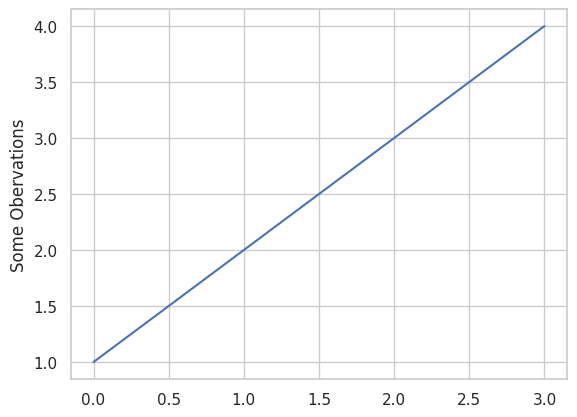

In [129]:
# Data Visualization Basics
import matplotlib.pyplot as plt
plt.plot([1,2,3,4])
plt.ylabel("Some Obervations")
plt.show()

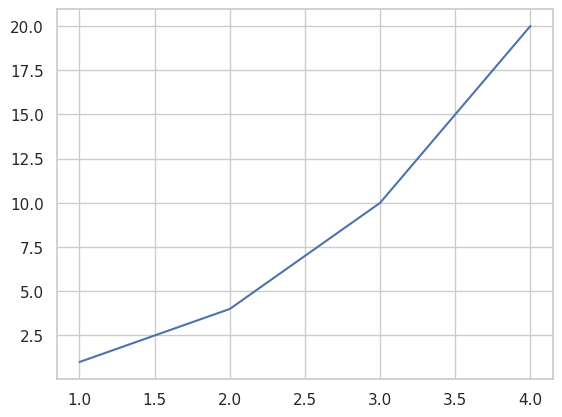

In [132]:
plt.plot([1,2,3,4], [1,4,10,20])

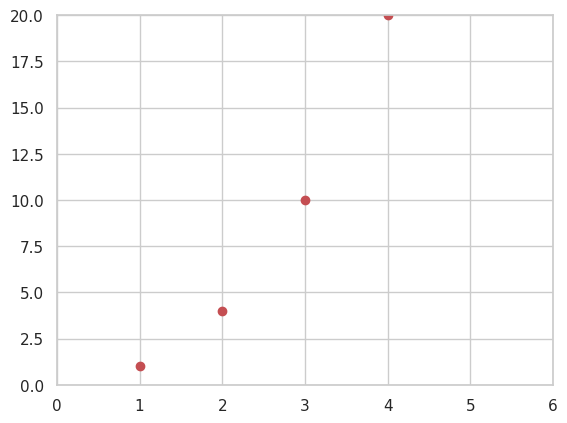

In [138]:
# Formating the style of plot
plt.plot([1,2,3,4], [1,4,10,20], 'ro')
plt.axis((0,6,0,20))
plt.show()


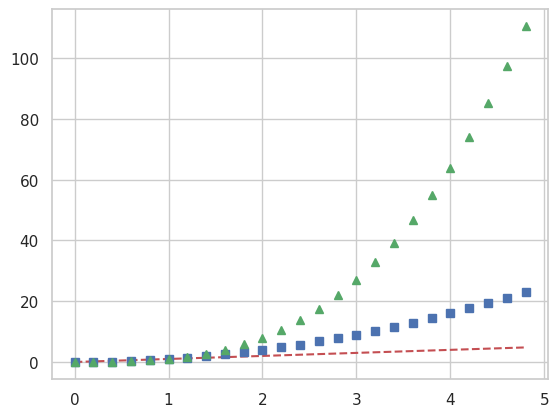

In [141]:
import numpy as np
t = np.arange(0., 5., 0.2)
plt.plot(t, t, 'r--', t, t**2, 'bs', t, t**3, 'g^')
plt.show()

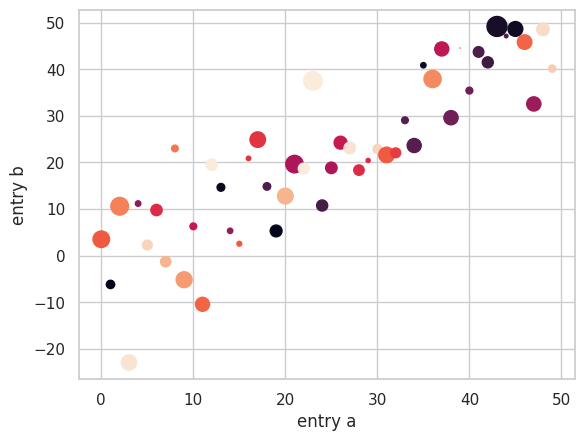

In [144]:
data = {'a': np.arange(50),
        'c': np.random.randint(0, 50, 50),
        'd': np.random.randn(50)}
data['b'] = data['a'] + 10 * np.random.randn(50)
data['d'] = np.abs(data['d']) * 100

plt.scatter('a', 'b', c='c', s='d', data= data)
plt.xlabel('entry a')
plt.ylabel('entry b')
plt.show()

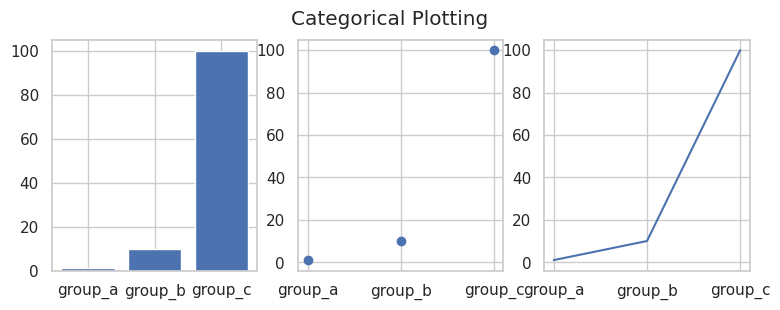

In [145]:
# Categrorical variables visualizations
names = ['group_a', 'group_b', 'group_c']
values = [1, 10, 100]
plt.figure(figsize=(9, 3))
plt.subplot(131)
plt.bar(names, values)
plt.subplot(132)
plt.scatter(names, values)
plt.subplot(133)
plt.plot(names, values)
plt.suptitle('Categorical Plotting')
plt.show()

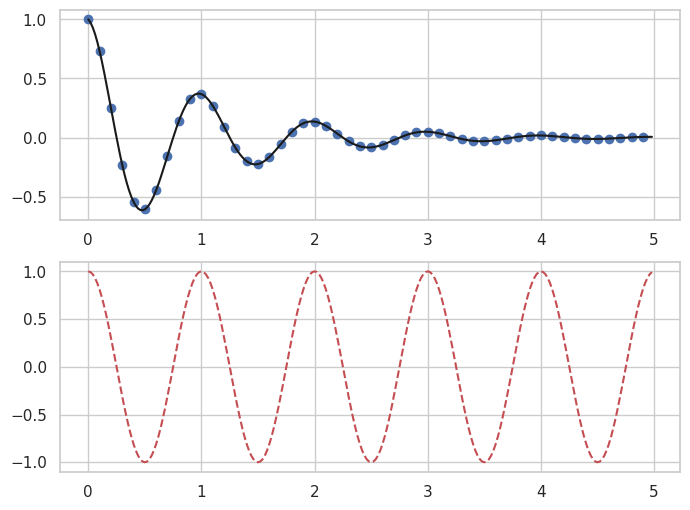

In [151]:
import numpy as np
import matplotlib.pyplot as plt

def f(t):
    return np.exp(-t) * np.cos(2*np.pi*t)

t1 = np.arange(0.0, 5.0, 0.1)
t2 = np.arange(0.0, 5.0, 0.02)

plt.figure(figsize=(8, 6))
plt.subplot(211)
plt.plot(t1, f(t1), 'bo', t2, f(t2), 'k')

plt.subplot(212)
plt.plot(t2, np.cos(2*np.pi*t2), 'r--')
plt.show()

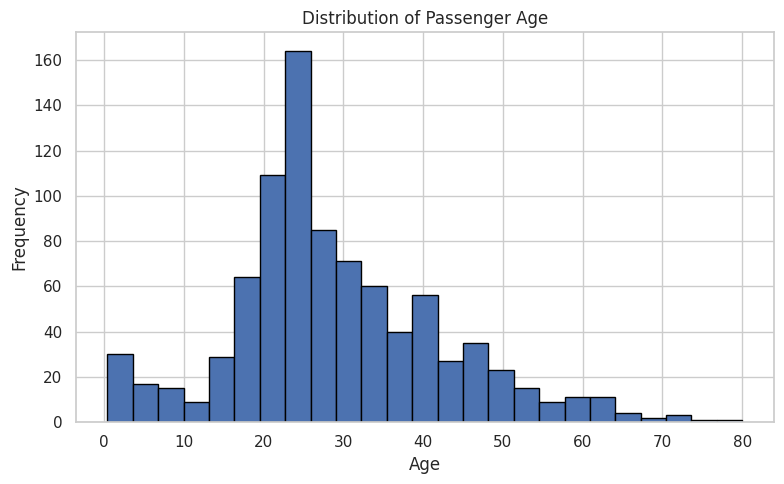

In [152]:
# Create a new figure.
plt.figure(figsize=(8, 5))

# Plot the age distribution.
plt.hist(
    titanic["age"],
    bins=25,
    edgecolor="black"
)

# Add labels.
plt.title("Distribution of Passenger Age")
plt.xlabel("Age")
plt.ylabel("Frequency")

# Improve spacing.
plt.tight_layout()

# Display the figure.
plt.show()

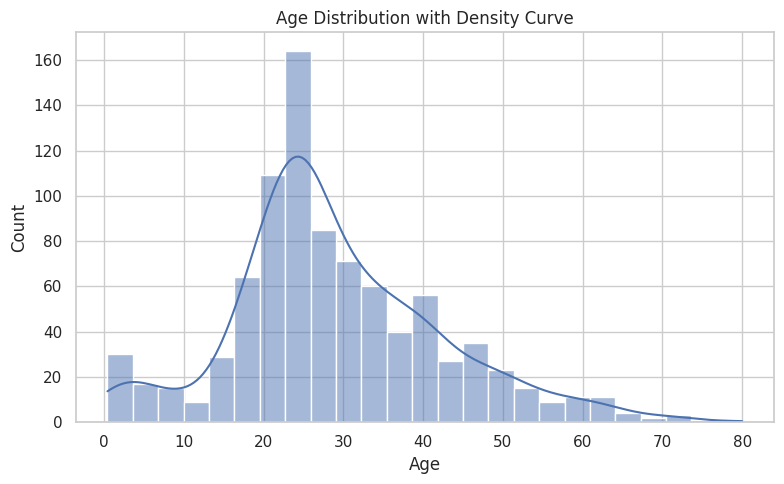

In [158]:
import seaborn as sns
sns.set_style("whitegrid")
plt.figure(figsize=(8,5))
sns.histplot(
    data=titanic,
    x="age",
    bins = 25,
    kde = True,
    color = DEFAULT_COLOR
)
plt.title("Age Distribution with Density Curve")
plt.xlabel("Age")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

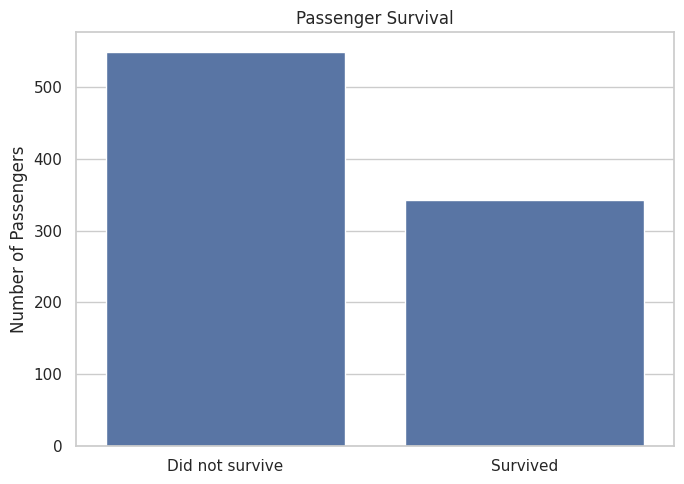

In [159]:
# Count Plot
plt.figure(figsize=(7, 5))

sns.countplot(
    data=titanic,
    x="survival_label",
    color=DEFAULT_COLOR
)

plt.title("Passenger Survival")
plt.xlabel("")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()

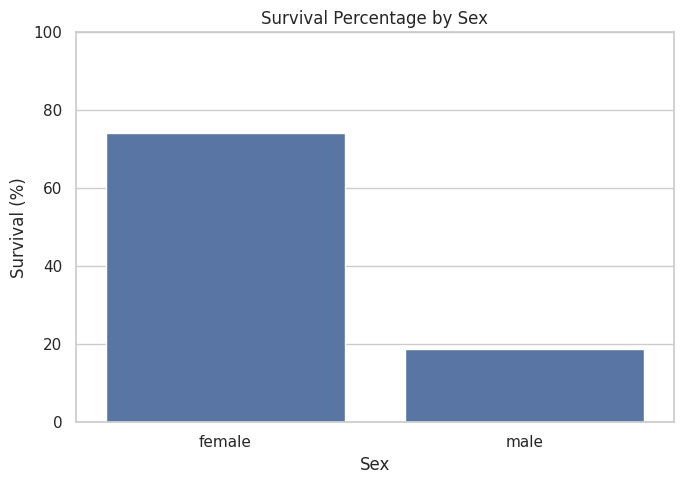

In [160]:
# Bar Plot — Survival Rate by Sex
# Calculate survival percentage by sex.
plot_data = (
    titanic
    .groupby("sex", observed=False)["survived"]
    .mean()
    .mul(100)
    .reset_index(name="survival_percent")
)

plt.figure(figsize=(7, 5))

sns.barplot(
    data=plot_data,
    x="sex",
    y="survival_percent",
    color=DEFAULT_COLOR
)

plt.title("Survival Percentage by Sex")
plt.xlabel("Sex")
plt.ylabel("Survival (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


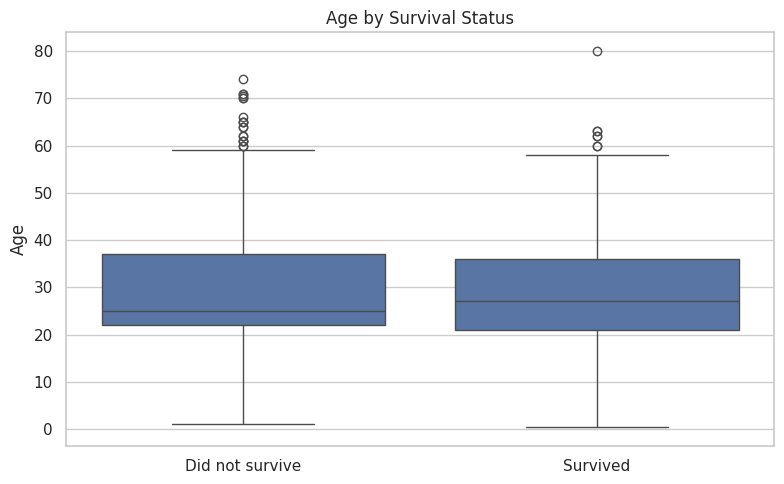

In [162]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=titanic,
    x="survival_label",
    y="age"
)

plt.title("Age by Survival Status")
plt.xlabel("")
plt.ylabel("Age")
plt.tight_layout()
plt.show()

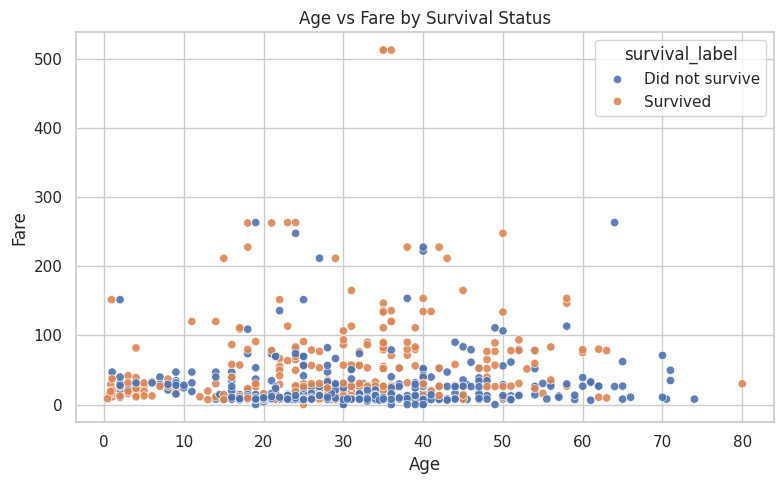

In [165]:
# Scatter Plot
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=titanic,
    x="age",
    y="fare",
    hue="survival_label",
    alpha=0.9
)

plt.title("Age vs Fare by Survival Status")
plt.xlabel("Age")
plt.ylabel("Fare")
plt.tight_layout()
plt.show()

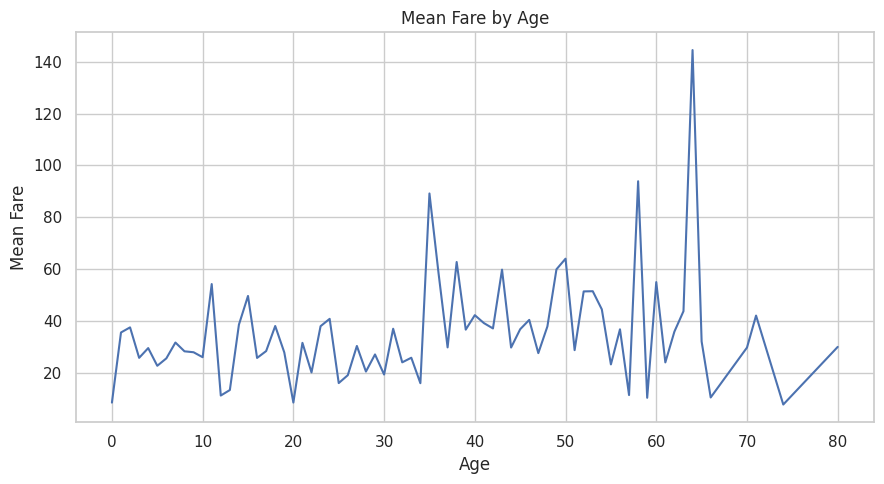

In [166]:
#  Line Plot

# Aggregate mean fare by age rounded to whole years.
age_fare = (
    titanic
    .assign(age_year=titanic["age"].round().astype(int))
    .groupby("age_year", as_index=False)["fare"]
    .mean()
)

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=age_fare,
    x="age_year",
    y="fare"
)

plt.title("Mean Fare by Age")
plt.xlabel("Age")
plt.ylabel("Mean Fare")
plt.tight_layout()
plt.show()

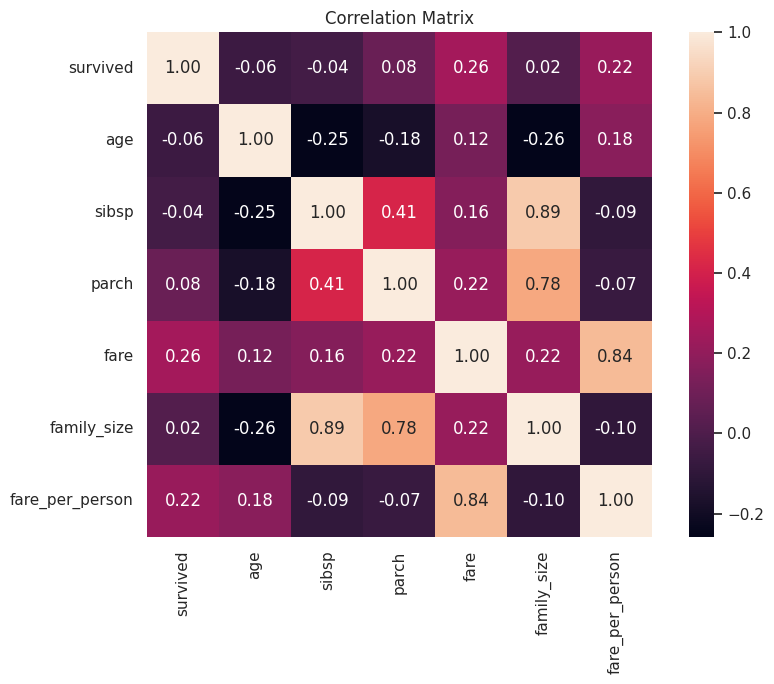

In [167]:
# Correlation Heatmap
# Select numeric variables for correlation.
corr_vars = [
    "survived",
    "age",
    "sibsp",
    "parch",
    "fare",
    "family_size",
    "fare_per_person"
]

# Calculate Pearson correlations.
corr_matrix = titanic[corr_vars].corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    square=True
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

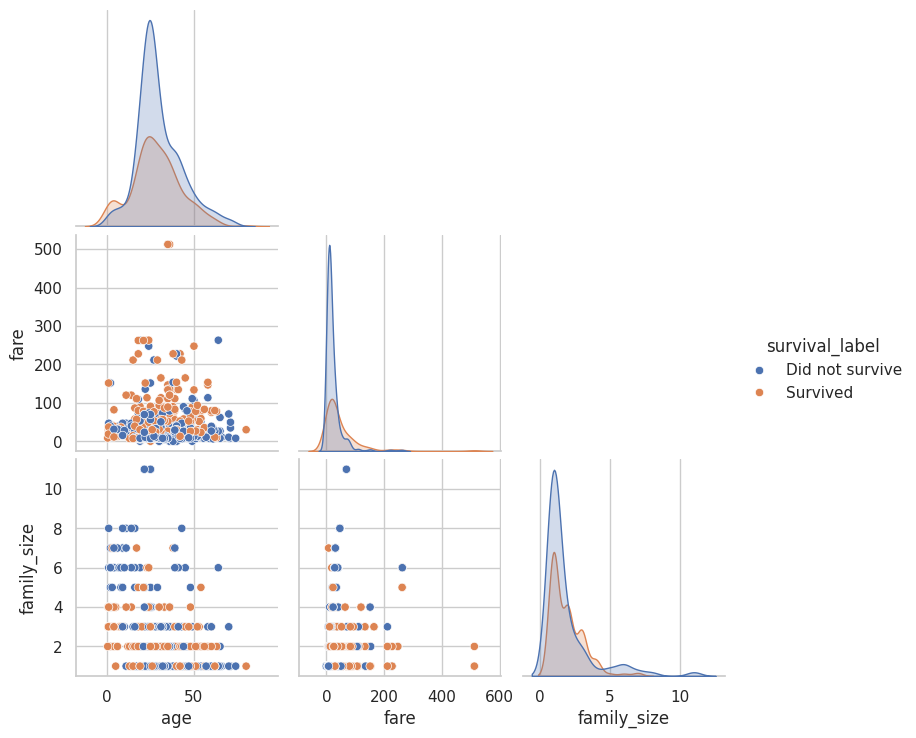

In [168]:
# Pair Plot

# Use a selected set of variables to keep the plot readable.
pair_data = titanic[
    ["age", "fare", "family_size", "survival_label"]
].copy()

sns.pairplot(
    pair_data,
    hue="survival_label",
    corner=True
)

plt.show()

In [169]:
# Exploratory Data Analysis (EDA)
# Univariate EDA
# Univariate summary for age.
print(titanic["age"].describe())

# Distribution shape.
print("\nSkewness:", titanic["age"].skew())

# Age-group frequencies.
print("\nAge-group frequencies:")
print(titanic["age_group"].value_counts())

count    891.000000
mean      29.112424
std       13.304424
min        0.420000
25%       21.500000
50%       26.000000
75%       36.000000
max       80.000000
Name: age, dtype: float64

Skewness: 0.5340834483875482

Age-group frequencies:
age_group
Adult          752
Child          113
Older adult     26
Name: count, dtype: int64


In [170]:
# Bivariate EDA
# Survival percentage by sex.
survival_sex = pd.crosstab(
    titanic["sex"],
    titanic["survived"],
    normalize="index"
).mul(100)

survival_sex

survived,0,1
sex,,
female,25.796178,74.203822
male,81.109185,18.890815


In [171]:
# Survival percentage by passenger class.
survival_class = (
    titanic
    .groupby("pclass", observed=False)["survived"]
    .mean()
    .mul(100)
)

survival_class

,survived
pclass,
1,62.962963
2,47.282609
3,24.236253


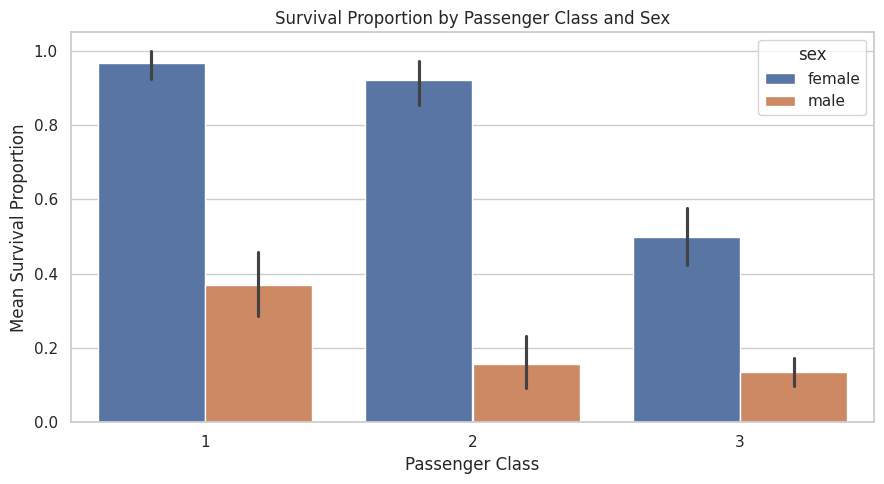

In [172]:
# Visualize survival by class with sex as a second grouping variable.
plt.figure(figsize=(9, 5))

sns.barplot(
    data=titanic,
    x="pclass",
    y="survived",
    hue="sex",
    errorbar=("ci", 95)
)

plt.title("Survival Proportion by Passenger Class and Sex")
plt.xlabel("Passenger Class")
plt.ylabel("Mean Survival Proportion")
plt.tight_layout()
plt.show()

In [173]:
# Raw counts.
sex_survival_counts = pd.crosstab(
    titanic["sex"],
    titanic["survival_label"]
)

sex_survival_counts

survival_label,Did not survive,Survived
sex,,
female,81,233
male,468,109
